# 1 Prepare Dataset and Label

Create Point in Google Earth Engine. If Posible ground truth data it is better.Export as raw data or Tiff.
Save to Google Drive Load Data in Colabs






In [ ]:
!pip install earthpy

In [ ]:
#IMPORT LIBRARY
#earth Library
import os
import glob
import pandas as pd
import numpy as np
# deep learning related imports
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, Flatten, Reshape, GlobalAveragePooling1D, GlobalMaxPooling1D
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Conv1D, MaxPooling1D
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
# visualization
import rasterio as rio
from rasterio.plot import show
import earthpy as et
import earthpy.spatial as es
import earthpy.plot as ep
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn import preprocessing
%matplotlib inline
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive')

/usr/local/lib/python3.13/dist-packages/earthpy/__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_string


Mounted at /content/drive


In [ ]:
# DEFINE GLOBAL Parameter
FEATURES = ['B4', 'B3', 'B2', 'B8', 'B11', 'B12', 'NDVI', "NDBI", 'MNDWI', 'NDSLI']
LABEL = ['class']
N_CLASSES = 7
CLASSES = [1, 2, 3, 4, 5, 6, 7]
PALETTE = ['#416422','#819A20', '#2389da', "#ff0000", '#ffffff', '#C2B280', '#808080']
CLASSNAMES = [
  "Vegetation",
  "Cultivation",
  "Water",
  "Urban",
  "Cloud",
  "Sand",
  "bare",
]
SAMPLE_PATH = '/content/drive/MyDrive/Colab Notebooks/lulc_samples.csv'

In [ ]:
df = pd.read_csv(SAMPLE_PATH)
# suffle train and test
np.random.seed(42)
df = df.sample(frac=1).reset_index(drop=True)
train = df[df['sample'] == 'train']
test = df[df['sample'] == 'test']
display(train);

,B4,B3,B2,B8,B11,B12,NDVI,NDBI,MNDWI,NDSLI,class,sample
0,0.04120,0.06405,0.08695,0.11360,0.07455,0.03370,0.467700,-0.207547,-0.075758,-0.288121,1,train
1,0.02920,0.04890,0.07470,0.06740,0.02770,0.01180,0.395445,-0.417455,0.276762,0.026362,1,train
2,0.04380,0.06990,0.08520,0.29630,0.15320,0.06180,0.742429,-0.318354,-0.373375,-0.555330,1,train
3,0.04260,0.06900,0.09470,0.03000,0.00860,0.00430,-0.173554,-0.554404,0.778351,0.664062,3,train
4,0.12955,0.13040,0.13510,0.23055,0.23210,0.17045,0.280478,0.003350,-0.280552,-0.283561,2,train
...,...,...,...,...,...,...,...,...,...,...,...,...
7036,0.10615,0.11930,0.12680,0.25400,0.20895,0.13760,0.410523,-0.097311,-0.273115,-0.326246,2,train
7037,0.08830,0.10210,0.12580,0.15750,0.14880,0.11300,0.281530,-0.028404,-0.186130,-0.255167,4,train
7038,0.11130,0.11480,0.12870,0.18590,0.19760,0.15480,0.251009,0.030508,-0.265045,-0.279378,4,train
7039,0.16550,0.16070,0.17190,0.18870,0.19320,0.15950,0.065500,0.011783,-0.091834,-0.077223,4,train


# 2 TRAIN THE MODEL

In [ ]:
# train and test datasets
train_x = train[FEATURES].to_numpy()
train_x = train_x.reshape(train_x.shape[0], train_x.shape[1], 1)
train_y = train[LABEL].to_numpy()
train_y = to_categorical(train_y, N_CLASSES+1)
print(train_x.shape);

test_x = test[FEATURES].to_numpy()
test_x = test_x.reshape(test_x.shape[0], test_x.shape[1], 1)
test_y = test[LABEL].to_numpy()
test_y = to_categorical(test_y, N_CLASSES+1)
print(train_x.shape, train_y.shape, test_x.shape, test_y.shape)

(6447, 10, 1)
(6447, 10, 1) (6447, 8) (594, 10, 1) (594, 8)


**Class Distribution in Training Set**

/tmp/ipykernel_728/1393634461.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis', ax=ax)


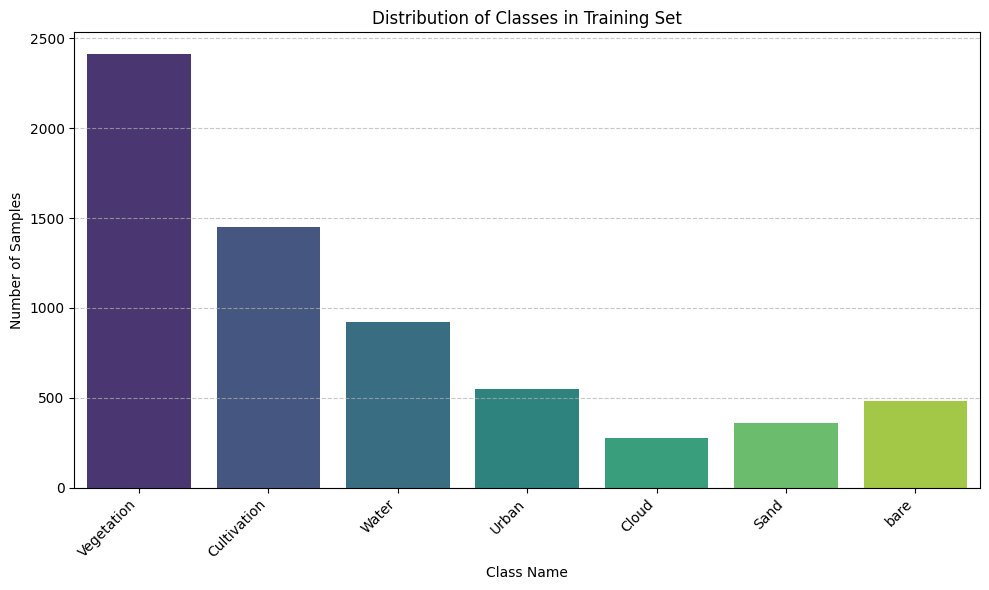

In [ ]:
# Get the actual class labels from one-hot encoded train_y
train_labels = np.argmax(train_y, axis=1)

# Count the occurrences of each class
class_counts = pd.Series(train_labels).value_counts().sort_index()

# Map class numbers to names for better readability
class_names_map = {i + 1: CLASSNAMES[i] for i in range(len(CLASSNAMES))}
class_counts.index = class_counts.index.map(class_names_map)

# Plot the distribution
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis', ax=ax)
plt.title('Distribution of Classes in Training Set')
plt.xlabel('Class Name')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Deep Learning Model**

In [ ]:
train_shape = train_x.shape
input_shape = (train_x.shape[1], train_x.shape[2])

print(input_shape)

# Make sequential model
model = keras.Sequential(name="model_conv1D")
model.add(keras.layers.Input(shape=input_shape))
model.add(keras.layers.Conv1D(filters=32, kernel_size=3, activation='relu', name="Conv1D_1"))
model.add(keras.layers.Dropout(0.1))
model.add(keras.layers.Conv1D(filters=16, kernel_size=3, activation='relu', name="Conv1D_2"))
model.add(keras.layers.Conv1D(filters=8, kernel_size=3, activation='relu', name="Conv1D_3"))
model.add(keras.layers.MaxPooling1D(pool_size=2, name="MaxPooling1D"))
model.add(keras.layers.Flatten())
model.add(keras.layers.Dense(64, activation='relu', name="Dense_1"))
model.add(keras.layers.Dense(32, activation='relu', name="Dense_2"))
model.add(keras.layers.Dense(N_CLASSES+1, name="Dense_3"))
model.add(keras.layers.Activation('softmax'))
model.summary()



(10, 1)


Model: "model_conv1D"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Conv1D_1 (Conv1D)               │ (None, 8, 32)          │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1D_2 (Conv1D)               │ (None, 6, 16)          │         1,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1D_3 (Conv1D)               │ (None, 4, 8)           │           392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1D (MaxPooling1D)     │ (None, 2, 8)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_1 (Dense)                 │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_3 (Dense)                 │ (None, 8)              │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 8)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,504 (21.50 KB)

 Trainable params: 5,504 (21.50 KB)

 Non-trainable params: 0 (0.00 B)

**Train the model**

In [ ]:
# compile
model.compile(
    optimizer='Adam',
    loss='CategoricalCrossentropy',
    metrics=['accuracy']
)

# Create callback to stop training if loss not decreasing
earlystop = EarlyStopping(
    monitor='loss',
    patience=5
)
modelcheckpoint = ModelCheckpoint(
    filepath='/content/drive/MyDrive/DL/1dcnn.h5',
    monitor='loss',
    save_best_only=True
)

# Fit the model
history = model.fit(
    x=train_x, y=train_y,
    validation_data=(test_x, test_y),
    batch_size=256,
    callbacks=[earlystop, modelcheckpoint],
    epochs=200,
)

Epoch 1/200
25/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3595 - loss: 2.0228

26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.3726 - loss: 1.9504 - val_accuracy: 0.1684 - val_loss: 1.9907
Epoch 2/200
25/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3931 - loss: 1.6209

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4106 - loss: 1.5371 - val_accuracy: 0.4343 - val_loss: 1.6202
Epoch 3/200
24/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5176 - loss: 1.2364

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5247 - loss: 1.1539 - val_accuracy: 0.5017 - val_loss: 1.1032
Epoch 4/200
25/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6479 - loss: 0.9091

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6963 - loss: 0.8245 - val_accuracy: 0.6313 - val_loss: 0.8370
Epoch 5/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7710 - loss: 0.6285

...

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9251 - loss: 0.2012 - val_accuracy: 0.8451 - val_loss: 0.4015
Epoch 97/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9248 - loss: 0.2056 - val_accuracy: 0.8569 - val_loss: 0.3914
Epoch 98/200
22/26 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9270 - loss: 0.2036

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9285 - loss: 0.1975 - val_accuracy: 0.8468 - val_loss: 0.3965
Epoch 99/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9286 - loss: 0.2005 - val_accuracy: 0.8552 - val_loss: 0.3956
Epoch 100/200
25/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9327 - loss: 0.1963

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9294 - loss: 0.1965 - val_accuracy: 0.8603 - val_loss: 0.4023
Epoch 101/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9283 - loss: 0.2002 - val_accuracy: 0.8822 - val_loss: 0.3766
Epoch 102/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9286 - loss: 0.1983 - val_accuracy: 0.8636 - val_loss: 0.3934
Epoch 103/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9245 - loss: 0.1994 - val_accuracy: 0.8805 - val_loss: 0.3603
Epoch 104/200
25/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9327 - loss: 0.1866

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9288 - loss: 0.1942 - val_accuracy: 0.8838 - val_loss: 0.3451
Epoch 105/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9254 - loss: 0.1958 - val_accuracy: 0.8569 - val_loss: 0.3712
Epoch 106/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9242 - loss: 0.1975 - val_accuracy: 0.8434 - val_loss: 0.4183
Epoch 107/200
25/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9310 - loss: 0.1840

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9296 - loss: 0.1896 - val_accuracy: 0.8721 - val_loss: 0.3725
Epoch 108/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9288 - loss: 0.1941 - val_accuracy: 0.8737 - val_loss: 0.3682
Epoch 109/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9242 - loss: 0.2020 - val_accuracy: 0.8620 - val_loss: 0.4062
Epoch 110/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9260 - loss: 0.1976 - val_accuracy: 0.8788 - val_loss: 0.3973
Epoch 111/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9246 - loss: 0.1981 - val_accuracy: 0.8603 - val_loss: 0.4342
Epoch 112/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9271 - loss: 0.1968 - val_accuracy: 0.8838 - val_loss: 0.3584


**EVALUATE MODEL**

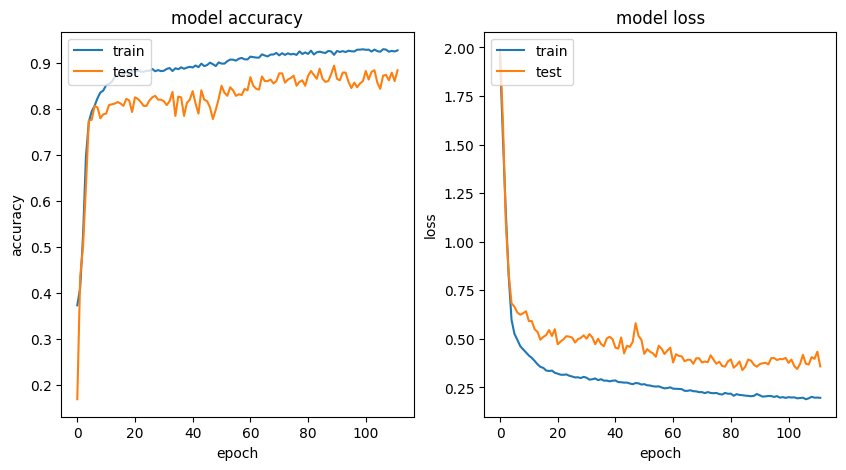

In [ ]:
#ACCURACY
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].plot(history.history['accuracy'])
ax[0].plot(history.history['val_accuracy'])
ax[0].set_title('model accuracy')
ax[0].set_ylabel('accuracy')
ax[0].set_xlabel('epoch')
ax[0].legend(['train', 'test'], loc='upper left')

ax[1].plot(history.history['loss'])
ax[1].plot(history.history['val_loss'])
ax[1].set_title('model loss')
ax[1].set_ylabel('loss')
ax[1].set_xlabel('epoch')
ax[1].legend(['train', 'test'], loc='upper left')

plt.show()

**TEST DATA**

In [ ]:
# load the best model
model = keras.models.load_model('/content/drive/MyDrive/DL/1dcnn.h5')

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
              precision    recall  f1-score   support

           1       1.00      1.00      1.00       100
           2       0.58      1.00      0.73        71
           3       0.93      0.98      0.95       169
           4       0.85      0.75      0.80        71
           6       0.99      0.82      0.90       154
           7       0.67      0.07      0.12        29

    accuracy                           0.87       594
   macro avg       0.84      0.77      0.75       594
weighted avg       0.89      0.87      0.86       594



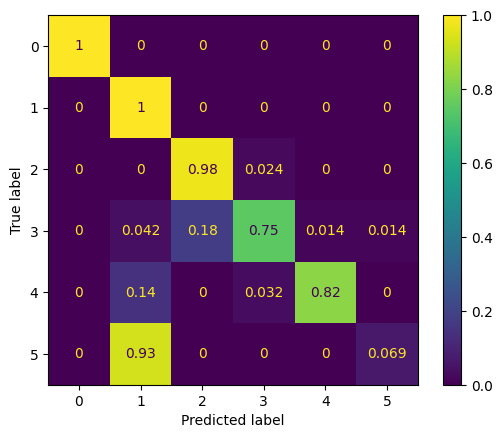

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict
prediction = np.argmax(model.predict(test_x), 1).flatten()
label = np.argmax(test_y, 1).flatten()

cm = classification_report(label, prediction)
print(cm)

# Confusion matrix
cm = confusion_matrix(label, prediction, normalize='true')
cm = ConfusionMatrixDisplay(cm)
cm.plot()


The model currently achieves an accuracy of 82%, which is a good start, but it's not yet reaching your target of 85%.

The primary reason for its current limitations is the imbalanced distribution of classes in your dataset.

Looking at the classification report, the model performs very well on classes like 'Water' and 'Vegetation', which are likely the most represented classes. However, it struggles significantly with minority classes



We need to make sure the training data is well-distributed and balanced across all classes. This can involve techniques like oversampling minority classes, undersampling majority classes, or using data augmentation.

After addressing the data imbalance, we should perform several tests and adjust the model's hyperparameters to further optimize its performance.

#3 INFERENCE MODEL

The 'INFERENCE MODEL' section describes the practical application of your trained model. In this phase, the model you've developed is used to predict land cover classes in new geographical areas.

The key aspects are:

1. Prediction on New Data:Instead of just evaluating the model on a test set, this step involves deploying it to make real-world predictions on satellite imagery from locations not included in your training data.
2. Direct Satellite Data Access: The approach of using 'direct data from satellite imagery' (likely through platforms like Google Earth Engine, which you've initialized) is highly efficient. It avoids the need to download large raw data files, streamlining the process and allowing for analysis of vast geographical areas.
3. Integration with Other Services: The mention of 'integration with another services' highlights the model's potential to be a component within a larger system. For instance, the land cover classification results could feed into environmental monitoring systems, urban planning tools, or agricultural management platforms, enabling automated insights and decision-making.

In [ ]:
#1 Package imports
import numpy as np
# deep learning related imports
import tensorflow as tf
from tensorflow import keras
import rasterio as rio
from rasterio.plot import show
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import from_levels_and_colors
from PIL import Image

import ee
import geemap
# Initialize Earth Engine
ee.Authenticate()
ee.Initialize(project='titanium-spider-379808')


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


In [ ]:
model = keras.models.load_model('/content/drive/MyDrive/DL/1dcnn.h5')
OUTPUT_PATH = '/content/drive/MyDrive/Colab Notebooks/predicted_map.tif'

FEATURES = ['B4', 'B3', 'B2', 'B8', 'B11', 'B12', 'NDVI', "NDBI", 'MNDWI', 'NDSLI']
LABEL = ['class']
N_CLASSES = 7
CLASSES = [1, 2, 3, 4, 5, 6, 7]
PALETTE = ['#416422','#819A20', '#2389da', "#ff0000", '#ffffff', '#C2B280', '#808080']
CLASS_LABELS = {
  1:"Vegetation",
  2:"Cultivation",
  3:"Water",
  4:"Urban",
  5:"Cloud",
  6:"Sand",
  7:"bare",
}

**DEFINE AOI and PREPARING DATA**

In [ ]:
#FUNCTIONs
# -------------------------------------------------------------------
# Cloud Mask Function
# -------------------------------------------------------------------
def maskS2clouds(image):

    qa = image.select("QA60")

    # Bits 10 and 11 are clouds and cirrus
    cloudBitMask = 1 << 10
    cirrusBitMask = 1 << 11

    mask = (
        qa.bitwiseAnd(cloudBitMask)
        .eq(0)
        .And(
            qa.bitwiseAnd(cirrusBitMask).eq(0)
        )
    )

    return image.updateMask(mask).divide(10000)

# -------------------------------------------------------------------
# Feature Extraction Function
# -------------------------------------------------------------------
def selectBands(image):

    # NDVI
    ndvi = (
        image.expression(
            "(NIR - RED) / (NIR + RED)",
            {
                "NIR": image.select("B8"),
                "RED": image.select("B4"),
            },
        )
        .rename("NDVI")
    )

    # NDBI
    ndbi = (
        image.expression(
            "(SWIR - NIR) / (SWIR + NIR)",
            {
                "NIR": image.select("B8"),
                "SWIR": image.select("B11"),
            },
        )
        .rename("NDBI")
    )

    # NDWI
    ndwi = (
        image.expression(
            "(GREEN - NIR) / (GREEN + NIR)",
            {
                "GREEN": image.select("B3"),
                "NIR": image.select("B8"),
            },
        )
        .rename("NDWI")
    )

    # NDSLI
    ndsli = (
        image.expression(
            "(RED - SWIR1) / (RED + SWIR1)",
            {
                "RED": image.select("B4"),
                "SWIR1": image.select("B11"),
            },
        )
        .rename("NDSLI")
    )

    # Required bands
    bands = ["B4", "B3", "B2", "B8", "B11", "B12"]

    image = image.select(bands)

    # Add feature bands
    image = image.addBands(
        ee.Image([ndvi, ndwi, ndbi, ndsli])
    )

    return image

In [ ]:
Map = geemap.Map(basemap='HYBRID')
Map.setCenter(100.03890477442907,13.822964171445545, 10)
Map

Map(center=[13.822964171445545, 100.03890477442907], controls=(WidgetControl(options=['position', 'transparent…

In [ ]:
aoi = Map.user_roi

In [ ]:
aoi = ee.Geometry.Polygon(
    [[[100.30278101834709, 13.780966653811968],
          [100.30209437283928, 13.769962885225425],
          [100.30947581204826, 13.762460018760606],
          [100.32123461636955, 13.763460414862775],
          [100.32810107144768, 13.768128873430223],
          [100.32724276456291, 13.786134911698927],
          [100.3089608279174, 13.785217971064691]]])
start_date="2026-06-01"
end_date="2026-09-30"

dataset = (
    ee.ImageCollection("COPERNICUS/S2_HARMONIZED")
    .filterDate(start_date,end_date)
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))
    .filterBounds(aoi)
    .map(maskS2clouds)
)
image_count = dataset.size().getInfo()
print(f"Jumlah citra dalam koleksi: {image_count}")
imagery = (
    dataset.map(
        lambda img: img.clip(aoi)
    )
    .median()
)
imagery = selectBands(imagery)

#4 EXPORT IMAGE to NUMPY =========
img_np = geemap.ee_to_numpy(
    imagery,
    region=aoi,
    scale=10
    #it make lower resolutioin, because the limitation with gee
    #to get best resolution, imagery upload to gdrive first then call in the model
)
rgb = img_np[:, :, :3]



Jumlah citra dalam koleksi: 3


**PREDICT**

In [ ]:
#5 PREDICTION =========
# Reshape (H, W, 10) -> (H * W, 10, 1)
img_to_predict = img_np.reshape(-1, 10, 1)
print(img_np.shape)
print(img_to_predict.shape)
# Predict
prediction = model.predict(img_to_predict, batch_size=1024*1024)
prediction = np.argmax(prediction, axis=1)
# Reshape back to 2D
prediction = prediction.reshape(img_np.shape[0], img_np.shape[1])

(264, 291, 10)
(76824, 10, 1)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 243ms/step


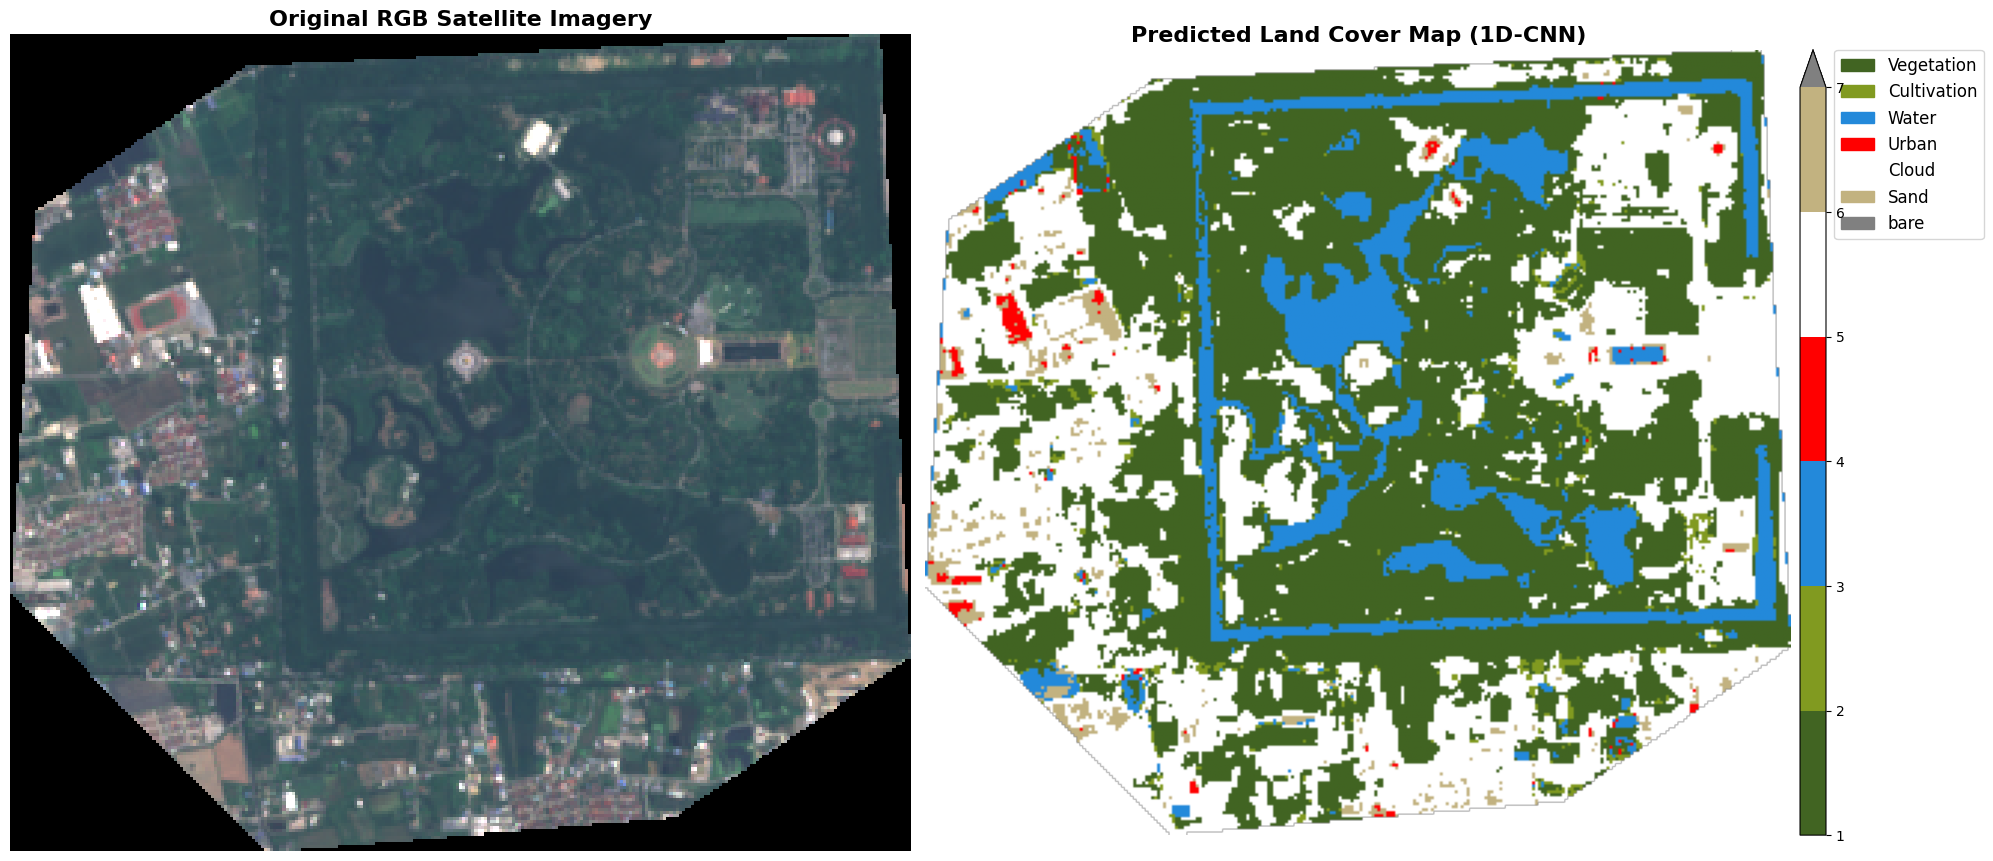

In [ ]:
from rasterio.features import geometry_mask
from rasterio.transform import from_bounds

# Set up the figure for side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# 1. Plot the Original RGB Satellite Imagery
# rgb array comes from the latest downloaded image
rgb_normalized = np.clip(rgb, 0, 0.3) / 0.3  # Standard stretch adjustment for Sentinel-2 reflectance
ep.plot_rgb(rgb_normalized.transpose(2, 0, 1), ax=axes[0])
axes[0].set_title('Original RGB Satellite Imagery', fontsize=16, fontweight='bold')
axes[0].axis('off')

# 2. Plot the Predicted Land Cover Map
# Calculate aoi_mask dynamically based on the current shape of 'prediction'
bounds = aoi.bounds().getInfo()["coordinates"][0]
xmin, ymin = bounds[0][0], bounds[0][1]
xmax, ymax = bounds[2][0], bounds[2][1]
height, width = prediction.shape
transform = from_bounds(xmin, ymin, xmax, ymax, width, height)

dynamic_aoi_mask = geometry_mask(
    [aoi.getInfo()],
    transform=transform,
    invert=True,       # True = inside AOI
    out_shape=(height, width)
)

clipped_prediction = np.where(dynamic_aoi_mask, prediction, 0)

cmap, norm = from_levels_and_colors(CLASSES, PALETTE, extend='max')
patches = [
    mpatches.Patch(color=PALETTE[i], label=CLASS_LABELS[CLASSES[i]])
    for i in range(len(CLASSES))
]

ep.plot_bands(clipped_prediction, cmap=cmap, norm=norm, ax=axes[1])
axes[1].set_title('Predicted Land Cover Map (1D-CNN)', fontsize=16, fontweight='bold')
axes[1].legend(handles=patches, bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0., fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()

**Create Predicted Tiff**

In [ ]:
from rasterio.features import geometry_mask
from rasterio.transform import from_bounds
# AOI bounds
bounds = aoi.bounds().getInfo()["coordinates"][0]
xmin = bounds[0][0]
ymin = bounds[0][1]
xmax = bounds[2][0]
ymax = bounds[2][1]
height, width = prediction.shape
transform = from_bounds(
    xmin,
    ymin,
    xmax,
    ymax,
    width,
    height
)

# Create AOI mask
aoi_mask = geometry_mask(
    [aoi.getInfo()],
    transform=transform,
    invert=True,       # True = inside AOI
    out_shape=(height, width)
)
# Map the prediction map to the RGB colors defined by your cmap & norm
cmap, norm = from_levels_and_colors(CLASSES, PALETTE, extend='max')
colors_rgba = cmap(norm(prediction))  # returns shape (H, W, 4) in range [0.0, 1.0]
colors_rgb = (colors_rgba[:, :, :3] * 255).astype(np.uint8)  # convert to uint8 (H, W, 3)
rgba = np.zeros(
    (height, width, 4),
    dtype=np.uint8
)
rgba[:, :, :3] = colors_rgb

# Alpha channel
rgba[:, :, 3] = np.where(
    aoi_mask,
    255,   # visible
    0      # transparent
)

rgba = rgba.transpose(2, 0, 1)

with rio.open(
    OUTPUT_PATH,
    "w",
    driver="GTiff",
    height=height,
    width=width,
    count=4,
    dtype="uint8",
    crs="EPSG:4326",
    transform=transform,
    compress="lzw"
) as dst:

    dst.write(rgba)

image_meta:  {'driver': 'GTiff', 'dtype': 'uint8', 'nodata': None, 'width': 1088, 'height': 854, 'count': 4, 'crs': CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]'), 'transform': Affine(8.977481617646627e-05, 0.0, 100.449028,
       0.0, -8.97517564402816e-05, 13.947895)}


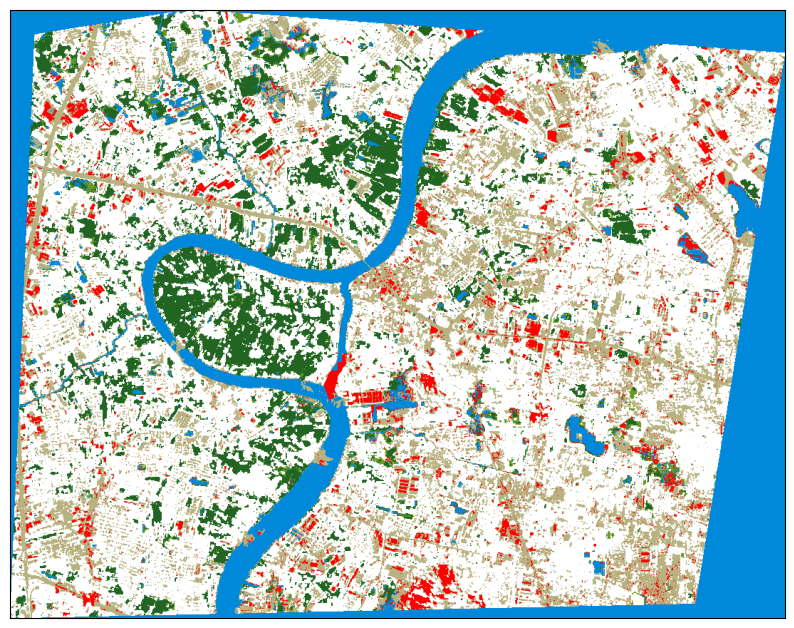

<Axes: >

In [ ]:
IMAGE_PATH = '/content/drive/MyDrive/Colab Notebooks/predicted_map.tif'
img = rio.open(IMAGE_PATH)
print('image_meta: ', img.meta)
full_img = img.read()
rgb = full_img[0:3]

ep.plot_rgb(rgb, figsize=(10, 10), stretch=True)

# STATIC

In [ ]:
# Parameter
FEATURES = ['B4', 'B3', 'B2', 'B8', 'B11', 'B12', 'NDVI', "NDBI", 'MNDWI', 'NDSLI']
LABEL = ['class']
N_CLASSES = 7
CLASSES = [1, 2, 3, 4, 5, 6, 7]
PALETTE = ['#416422','#819A20', '#2389da', "#ff0000", '#ffffff', '#C2B280', '#808080']
model = keras.models.load_model('/content/drive/MyDrive/DL/1dcnn.h5')

image_meta:  {'driver': 'GTiff', 'dtype': 'float32', 'nodata': None, 'width': 750, 'height': 765, 'count': 10, 'crs': CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]'), 'transform': Affine(8.983152841195215e-05, 0.0, 100.18074930570792,
       0.0, -8.983152841195215e-05, 14.016862535758953)}


/usr/local/lib/python3.13/dist-packages/earthpy/spatial.py:561: RuntimeWarning: invalid value encountered in cast
  return (bytedata.clip(low, high) + 0.5).astype("uint8")


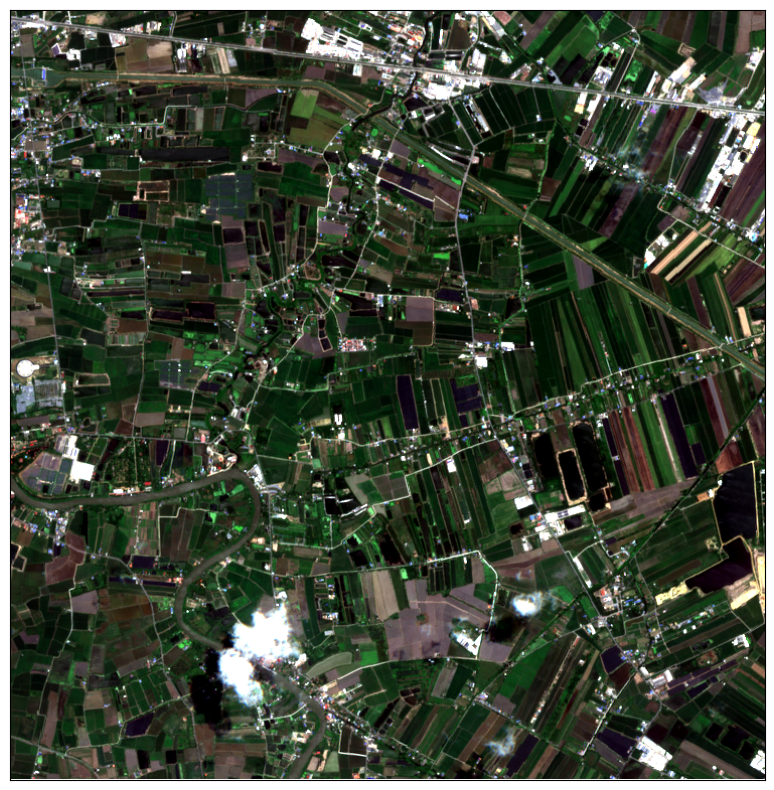

<Axes: >

In [ ]:
# load image
img = rio.open('/content/drive/MyDrive/Colab Notebooks/s2_nakhon.tif')
print('image_meta: ', img.meta)
full_img = img.read()
rgb = full_img[0:3]

ep.plot_rgb(rgb, figsize=(10, 10), stretch=True)



In [ ]:
from matplotlib.colors import from_levels_and_colors

# Reshape to (height * width, bands, 1) to match the model's input shape
img_to_predict = full_img.transpose(1, 2, 0).reshape(full_img.shape[1] * full_img.shape[2], full_img.shape[0], 1)
print(img_to_predict.shape)

# Predict
prediction = model.predict(img_to_predict, batch_size=1024*1024)
prediction = np.argmax(prediction, 1)

(573750, 10, 1)
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


<matplotlib.colors.ListedColormap object at 0x7cf36b4dd790> <matplotlib.colors.BoundaryNorm object at 0x7cf36b448910>


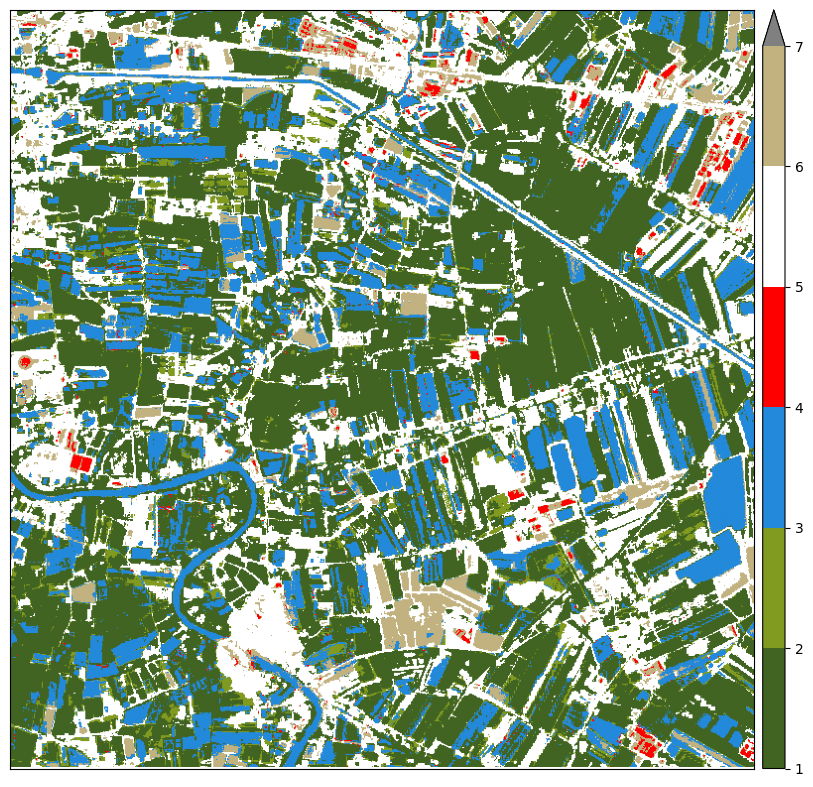

<Axes: >

In [ ]:
prediction = prediction.reshape(full_img.shape[1], full_img.shape[2])

# Visualize
cmap, norm = from_levels_and_colors(CLASSES, PALETTE, extend='max')
print(cmap, norm)
ep.plot_bands(prediction, cmap=cmap, norm=norm, figsize=(10, 10))